# Useful modules import

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.io
import pandas as pd
import ipywidgets as widgets
from tensorflow import keras
from tensorflow.keras import layers
from keras.utils import to_categorical
import os
import math
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import random

Installo il pacchetto: [mne](https://mne.tools/stable/index.html): Open-source Python package for exploring, visualizing, and analyzing human neurophysiological data like EEG.

In [ ]:
!pip install mne
import mne

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 37.2 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**A Deep Neural Network for decoding Motor Imagery Movements from EEG signals of stroke patients.**

- **Descrizione del problema:** Classificazione della volontà di azione di movimento ‘mano sinistra‘ e ‘mano destra’ basata sul segnale Elettroencefalografico (EEG) di 50 soggetti con ictus cerebrale. Durante l’esecuzione del ‘motor imagery task’ i soggetti immaginano di muovere la mano destra o sinistra in base all'istruzione mostrata su di uno schermo davanti a loro.

- **Il Dataset:** Il dataset a disposizione: 29 segnali Elettroencefalografici (EEG) + 2 segnali Elettrooculografici (EoG) (questi ultimi utilizzati per il pre-processing del segnale EEG, nello specifico per la rimozione di artefatti oculari) di 50 pazienti che hanno avuto un ictus cerebrale. Il dataset è composto da 2000 trials in totale => 50 soggetti x 40 trials (20 trials per la mano sinistra e 20 per la mano destra), con una durata di 8 secondi per trial. Ogni trial si compone di: istruzione sullo schermo (2s), immaginazione del movimento (4s), Break(2s).


![the experiment design](https://drive.google.com/uc?export=view&id=1TT5kgmD68CtO355KV3MkZq7sDEPsrS3T)



**Data processing:**

Utilizzo i dati EEG già pre-processati dagli autori dell’articolo.
- **Tecnica delle sliding windows**: Per ovviare al problema dei pochi dati (2000 trials), da questi selezionerò solo i segmenti legati all'immaginazione del movimento da 4s (i quali dovrebbero portare con sé gran parte dell'informazione relativa al tipo di movimento) e li dividerò in un determinato numero di finestre temporali. La lunghezza delle finestre temporali verrà trattato come iper-parametro successivamente.
- **Splitting dei dati** in Training-Validation-Test set con un rapporto di 30-10-10 soggetti rispettivamente. Verranno rispettate le proporzioni di sesso e paralisi cerebrale.
- **Normalizzazione** dei dati

**Training**

Sviluppo e addestramento di una rete RNN.

-  [Articolo di riferimento](https://www.nature.com/articles/s41597-023-02787-8)

# Utility functions
- **Sliding_windows_dataset**: *funzione che prende in input un dataset in forma di lista di ID, importa i dati EEG dei soggetti del dataset e divide i trials in finestrelle di lunghezza specificata (no sovrapposizione delle finestre)*.
- **plot_eeg**: *Plot del segnale EEG*.
- **determine_delta**: *funzione che determina il valore **delta** dalla distribuzione dei dati EEG del dataset dato in input. Questo valore viene poi dato in input alla funzione 'plot_eeg' per separare i channels verticalmente sulll'asse y. Utile per comparare visivamente i dati EEG prima e dopo la normalizzazione.*
- **plot_2features**: *Plot dei dati after PCA/TSNE in 2D*
- **plot_history**: *Plot del trend della loss sulle epoche del training e validation set.*

In [ ]:
def Sliding_windows_dataset(lista_ID, lista_onset, lista_labels, n_windows):
  """
    Input della funzione:
    - lista_ID: lista dei 'Participant_ID'
    - lista_onset: lista di valori che rappresentano l'onset del motor imagery task in time_sample
    - lista_labels: lista di valori corrispondenti a 1 (left) o 2 (right)
    - n_windows: numero di windows per ogni trial da 4 secondi (2000 time_samples = trial_length)

    Output della funzione:
    - dataset_w: tensore di shape: esempi_dataset x channels x window_length
    - dataset_labels_w: vettore riga che contiene le labels di ogni esempio, shape: esempi_dataset x 1
  """
  trial_length = 2000 # ci sono 2000 time samples all'interno di 4 secondi di trial
  eeg_subjects = []  #inizializiamo una lista vuota che conterrà tutti i dati EEG dei soggetti in lista_ID

  # CARICAMENTO DEI DATI
  for i in range(len(lista_ID)):
    edf_file_path = '/content/eeg_data/' + lista_ID[i]  +'_task-motor-imagery_eeg.edf'
    raw = mne.io.read_raw_edf(edf_file_path)
    eeg_subj = raw.get_data()  # EEG del singolo soggetto
    #Rimozione dei segnali non utili (gli ultimi 3 channels (2 channels EoG + 1 marker event channel))
    eeg_subjects.append(eeg_subj[0:-3,:])  # aggiorniamo la lista

  lista_eeg_dataset = [] # Inizializzo la lista delle windows dell'intero dataset dato in input (tramite lista_ID)
  lista_labels_dataset = [] # Inizializzo la lista delle labels dell'intero dataset dato in input
  window_length = trial_length//n_windows

  # CREAZIONE DELLE SLIDING WINDOWS
  for i in range(len(eeg_subjects)):

      EEG = eeg_subjects[i]
      trials_w = []  # Inizializzo la lista delle windows per ogni soggetto
      lista_labels_w = [] # Inizializzo la lista delle labels per ogni soggetto

      for j,onset in enumerate(lista_onset):
        for k in range(n_windows):

          start = onset + window_length * k
          end = onset + window_length * (k + 1)
          lista_labels_w.append(lista_labels[j])  # creo la nuova lista di labels
          segment = EEG[:, start : end]  # ad ogni iterazione questo sarà un vettore di shape (30 channels x window_length)
          trials_w.append(segment)  # questo crea una lista di matrici (30 channels x window_length)

      eeg_subj_tensor_w = np.stack(trials_w, axis=0)
      lista_eeg_dataset.append(eeg_subj_tensor_w)  # aggiorno la lista che mette insieme le sliding windows dei vari soggetti del dataset dato in input
      lista_labels_dataset.append(lista_labels_w) # aggiorno la lista che mette insieme le labels dei vari soggetti del dataset dato in input

  dataset_w = np.concatenate(lista_eeg_dataset, axis=0) # concateno i tensori lungo la prima dimensione in modo tale da avere: (windows x channels x time samples)
  dataset_labels_w = np.concatenate(lista_labels_dataset, axis=0) # concateno il vettore labels

  return dataset_w, dataset_labels_w



def plot_eeg(EEG_data, delta, title, eeg_channels, tstart, tend):
    n_channels = EEG_data.shape[0]
    plt.figure(figsize=(10, 6))
    for i in range(n_channels):
        channel_index = n_channels - i - 1  # Reverse the channel index to start from the top
        plt.plot(EEG_data[channel_index, tstart:tend] + i * delta)  # Offset each channel vertically for visualization
    plt.xlabel('Time (samples)')
    plt.ylabel('Amplitude')
    plt.title(title)
    plt.yticks(np.arange(n_channels) * delta, [f'{eeg_channels[i]}' for i in range(n_channels)])
    plt.grid(True)
    plt.show()


def determine_delta(EEG_data):
    # Calcolo il 25-esimo e il 75-esimo percentile
    Q1 = np.percentile(EEG_data, 25, axis=1)
    Q3 = np.percentile(EEG_data, 75, axis=1)
    IQR = Q3 - Q1   # interquartile range
    return np.median(IQR)


def plot_2features(data, labels, title):
  plt.scatter(data[labels == 1, 0], data[labels==1, 1], c='red', label='Sinistra', alpha=0.5)
  plt.scatter(data[labels == 2, 0], data[labels==2, 1], c='blue', label='Destra', alpha=0.5)
  plt.title(title)
  plt.xlabel('feature 1')
  plt.ylabel('feature 2')
  plt.legend()


def plot_history(history,metric=None):
  fig, ax1 = plt.subplots(figsize=(10, 8))

  epoch_count=len(history.history['loss'])

  line1,=ax1.plot(range(1,epoch_count+1),history.history['loss'],label='train_loss',color='orange')
  ax1.plot(range(1,epoch_count+1),history.history['val_loss'],label='val_loss',color = line1.get_color(), linestyle = '--')
  ax1.set_xlim([1,epoch_count])
  ax1.set_ylim([0, max(max(history.history['loss']),max(history.history['val_loss']))])
  ax1.set_ylabel('loss',color = line1.get_color())
  ax1.tick_params(axis='y', labelcolor=line1.get_color())
  ax1.set_xlabel('Epochs')
  _=ax1.legend(loc='lower left')

  if (metric!=None):
    ax2 = ax1.twinx()
    line2,=ax2.plot(range(1,epoch_count+1),history.history[metric],label='train_'+metric)
    ax2.plot(range(1,epoch_count+1),history.history['val_'+metric],label='val_'+metric,color = line2.get_color(), linestyle = '--')
    ax2.set_ylim([0, max(max(history.history[metric]),max(history.history['val_'+metric]))])
    ax2.set_ylabel(metric,color=line2.get_color())
    ax2.tick_params(axis='y', labelcolor=line2.get_color())
    _=ax2.legend(loc='upper right')

# DATASET

In [ ]:
# @title Caricamento delle caratteristiche del dataset
dataframe = pd.read_csv('/content/drive/MyDrive/PROGETTO D.L./Stroke dataset/participants.tsv', delimiter='\t')

In [ ]:
# @title Caricamento delle cartelle con i segnali EEG
root_folder = '/content/drive/MyDrive/PROGETTO D.L./Stroke dataset/edffile'
eeg_files = []  #Creo una lista vuota che mi serve per salvare i percorsi dei file EEG
for subject_folder in os.listdir(root_folder):
    eeg_folder = os.path.join(root_folder, subject_folder, 'eeg')
    eeg_files += [os.path.join(eeg_folder, f) for f in os.listdir(eeg_folder) if f.endswith('.edf')]

print("Found EEG files:")
print(eeg_files)
# eeg_files è la lista dei percorsi dei file EEG

import shutil

colab_eeg_folder = '/content/eeg_data'
os.makedirs(colab_eeg_folder, exist_ok=True)

for eeg_file in eeg_files:
    #copio il dataset in una cartella di Colab. (Si potrebbe anche evitare)
    shutil.copyfile(eeg_file, os.path.join(colab_eeg_folder, os.path.basename(eeg_file)))

print("EEG data files copied to Colab folder:", colab_eeg_folder)

Found EEG files:
['/content/drive/MyDrive/PROGETTO D.L./Stroke dataset/edffile/sub-28/eeg/sub-28_task-motor-imagery_eeg.edf', '/content/drive/MyDrive/PROGETTO D.L./Stroke dataset/edffile/sub-31/eeg/sub-31_task-motor-imagery_eeg.edf', '/content/drive/MyDrive/PROGETTO D.L./Stroke dataset/edffile/sub-13/eeg/sub-13_task-motor-imagery_eeg.edf', '/content/drive/MyDrive/PROGETTO D.L./Stroke dataset/edffile/sub-41/eeg/sub-41_task-motor-imagery_eeg.edf', '/content/drive/MyDrive/PROGETTO D.L./Stroke dataset/edffile/sub-36/eeg/sub-36_task-motor-imagery_eeg.edf', '/content/drive/MyDrive/PROGETTO D.L./Stroke dataset/edffile/sub-50/eeg/sub-50_task-motor-imagery_eeg.edf', '/content/drive/MyDrive/PROGETTO D.L./Stroke dataset/edffile/sub-33/eeg/sub-33_task-motor-imagery_eeg.edf', '/content/drive/MyDrive/PROGETTO D.L./Stroke dataset/edffile/sub-37/eeg/sub-37_task-motor-imagery_eeg.edf', '/content/drive/MyDrive/PROGETTO D.L./Stroke dataset/edffile/sub-12/eeg/sub-12_task-motor-imagery_eeg.edf', '/content/

In [ ]:
# @title Visualizzazione
row_count=5

dataframe.head(row_count)  # esempio delle prime 5 righe

,Participant_ID,Gender,Age,Duration,ParalysisSide,Handedness,IsFirstTime,StrokeLocation,NIHSS,MBI,mRS
0,sub-01,male,45,1,right,right,yes,Left pons,11,50,4
1,sub-02,male,60,2,left,right,yes,Right pons,3,55,4
2,sub-03,male,60,2,left,right,no,"Left cerebellum, bilateral paraventricular, Ri...",3,90,1
3,sub-04,male,56,14,right,right,yes,"Left frontal parietal cortex, Left centrum sem...",6,90,3
4,sub-05,female,44,4,left,right,yes,Left pons,4,60,4


In [ ]:
dataframe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Participant_ID  50 non-null     object
 1   Gender          50 non-null     object
 2   Age             50 non-null     int64 
 3   Duration        50 non-null     int64 
 4   ParalysisSide   50 non-null     object
 5   Handedness      50 non-null     object
 6   IsFirstTime     50 non-null     object
 7   StrokeLocation  50 non-null     object
 8   NIHSS           50 non-null     int64 
 9   MBI             50 non-null     int64 
 10  mRS             50 non-null     int64 
dtypes: int64(5), object(6)
memory usage: 4.4+ KB


In [ ]:
dataframe.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Age,50.0,56.70,10.573841,31.0,52.0,57.5,63.75,77.0
Duration,50.0,5.78,6.908410,1.0,2.0,3.0,6.00,30.0
NIHSS,50.0,4.16,2.852568,1.0,2.0,3.0,6.00,11.0
MBI,50.0,70.94,18.221326,32.0,55.0,70.0,85.00,100.0
mRS,50.0,2.68,1.448997,0.0,1.0,3.0,4.00,5.0


Mantengo soltanto le informazioni sul sesso, età e lato della paralisi

In [ ]:
# Elimino le colonne non prese in considerazione
df=dataframe.drop(['Duration','Handedness','IsFirstTime','StrokeLocation','NIHSS','MBI', 'mRS'],axis=1)
df.sample(row_count)

,Participant_ID,Gender,Age,ParalysisSide
48,sub-49,male,52,left
22,sub-23,male,57,left
39,sub-40,female,56,left
17,sub-18,female,60,left
5,sub-06,male,66,left


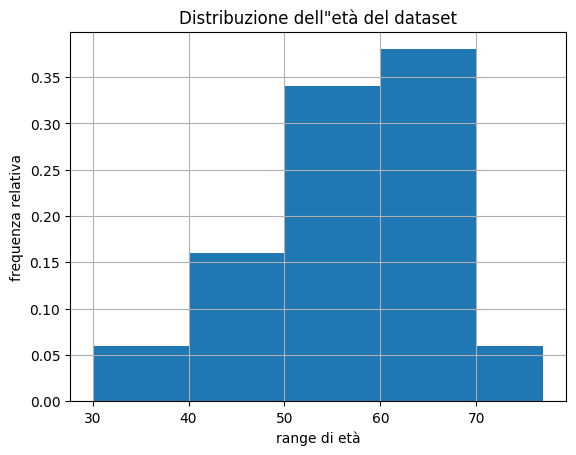

In [ ]:
# @title Distribuzione dell'età sull'intero dataset
bins = [30, 40, 50, 60, 70, df['Age'].max()]
df['Age'].hist(bins = bins, grid=True, weights=np.ones(len(df)) / len(df))
plt.title('Distribuzione dell"età del dataset')
plt.xlabel('range di età')
plt.ylabel('frequenza relativa')
plt.show()


In [ ]:
# @title Proporzioni di Sesso  & lato della paralisi
maschi_dx = df[(df['Gender'] == 'male') & (df['ParalysisSide'] == 'right')]
maschi_dx_perc = len(maschi_dx)/len(df)
maschi_sx = df[(df['Gender'] == 'male') & (df['ParalysisSide'] == 'left')]
maschi_sx_perc = len(maschi_sx)/len(df)

femmine_dx = df[(df['Gender'] == 'female') & (df['ParalysisSide'] == 'right')]
femmine_dx_perc = len(femmine_dx)/len(df)
femmine_sx = df[(df['Gender'] == 'female') & (df['ParalysisSide'] == 'left')]
femmine_sx_perc = len(femmine_sx)/len(df)

print('maschi con paralisi destra',maschi_dx_perc*100,'%')
print('maschi con paralisi sinistra',maschi_sx_perc*100,'%')
print('femmine con paralisi destra',femmine_dx_perc*100,'%')
print('femmine con paralisi sinistra',femmine_sx_perc*100,'%')

maschi con paralisi destra 34.0 %
maschi con paralisi sinistra 44.0 %
femmine con paralisi destra 10.0 %
femmine con paralisi sinistra 12.0 %


#  SPLITTING DEI DATI
**Rispetto le proporzioni di sesso e lato della paralisi**


Dataset Splitting:
- Training set 60% (30 soggetti)
- Validation set 20%  (10 soggetti)
- Test set 20%  (10 soggetti)

In [ ]:
# @title Training, validation, test set
df['Stratify'] = df['Gender'] + '-' + df['ParalysisSide']

seed = 33  # cambio questo valore per capire se dopo la distribuzione d'età nei tre set è accettabile
# seed = 33 è il migliore che ho trovato

# Splitto i data in training (60%) e temporary (40%)
train, temp = train_test_split(df, test_size=0.4, stratify=df['Stratify'], random_state=seed)

# Splitto i dati temporary in validation (50% di temporary) and test (50% di temporary)
validation, test = train_test_split(temp, test_size=0.5, stratify=temp['Stratify'], random_state=seed)


In [ ]:
# @title Verifica delle distribuzioni (sesso & lato della paralisi)
print("Training set distribution:")
print(train['Stratify'].value_counts(normalize=True))

print("Validation set distribution:")
print(validation['Stratify'].value_counts(normalize=True))

print("Test set distribution:")
print(test['Stratify'].value_counts(normalize=True))


Training set distribution:
Stratify
male-left       0.433333
male-right      0.333333
female-left     0.133333
female-right    0.100000
Name: proportion, dtype: float64
Validation set distribution:
Stratify
male-left       0.4
male-right      0.4
female-right    0.1
female-left     0.1
Name: proportion, dtype: float64
Test set distribution:
Stratify
male-left       0.5
male-right      0.3
female-left     0.1
female-right    0.1
Name: proportion, dtype: float64


Ora vedo se la distribuzione dell'età dei soggetti dell'intero dataset è rispettata all'interno dei tre set (Training, Validation e Test)

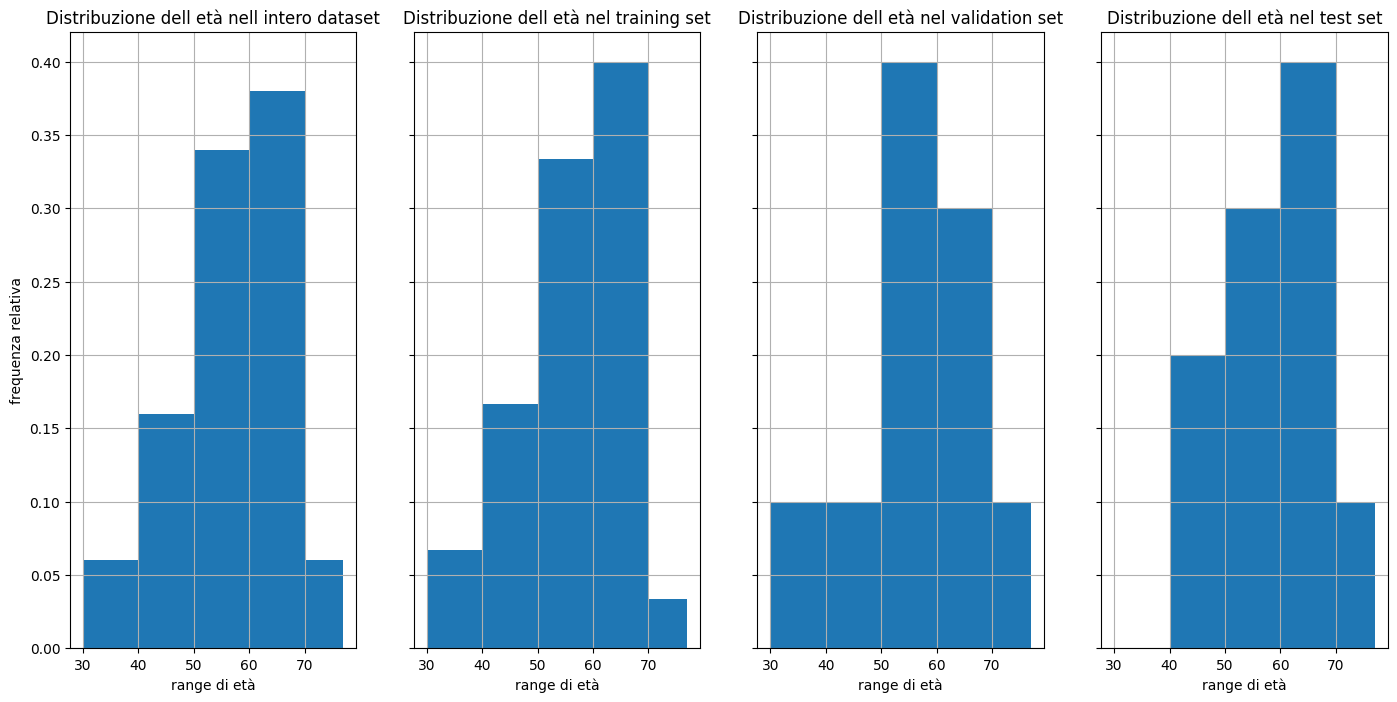

In [ ]:
# @title Verifica della distribuzione dell'età nei tre set
fig, axes = plt.subplots(1,4, figsize=(17, 8),sharex=True, sharey = True)

axes[0].hist(df['Age'],bins = bins, weights=np.ones(len(df)) / len(df))
axes[0].set_title('Distribuzione dell età nell'' intero dataset')
axes[0].set_xlabel('range di età')
axes[0].set_ylabel('frequenza relativa')
axes[0].grid(True)

axes[1].hist(train['Age'],bins = bins, weights=np.ones(len(train)) / len(train))
axes[1].set_title('Distribuzione dell età nel training set')
axes[1].set_xlabel('range di età')
axes[1].grid(True)

axes[2].hist(validation['Age'],bins = bins, weights=np.ones(len(validation)) / len(validation))
axes[2].set_title('Distribuzione dell età nel validation set')
axes[2].set_xlabel('range di età')
axes[2].grid(True)

axes[3].hist(test['Age'],bins = bins, weights=np.ones(len(test)) / len(test))
axes[3].set_title('Distribuzione dell età nel test set')
axes[3].set_xlabel('range di età')
axes[3].grid(True)

# Ho plottato la frequenza relativa in maniera tale da comparare visivamente le diverse distribuzioni

# Esempio di segnale EEG di un soggetto

La funzione della libreria mne: [mne.io.read_raw](https://mne.tools/stable/generated/mne.io.Raw.html)
estrapola dal file 'edf' alcune proprietà

In [ ]:
# gli 'edf' file rappresentano il segnale EEG già pre-processed
edf_file_path = '/content/eeg_data/sub-48_task-motor-imagery_eeg.edf'
raw = mne.io.read_raw_edf(edf_file_path)


Extracting EDF parameters from /content/eeg_data/sub-48_task-motor-imagery_eeg.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...


<ipython-input-16-76b5e7ec340c>:3: RuntimeWarning: Physical range is not defined in following channels:
CPz
  raw = mne.io.read_raw_edf(edf_file_path)


Il numero dei canali è 33, di cui 30 sono canali EEG (channel 18 è il reference channel), 2 canali EOG (31 horizontal EOG channels and 32 vertical EOG channels), and 1 canale 'marker event'

In [ ]:
# Qualche informazione riguardo ai dati EEG
print("Channel names:", raw.ch_names)
print('number of channels:',len(raw.ch_names))  #HEOL e HEOR sono elettrodi EoG (Electro-oculograms)

print("Sampling frequency:", raw.info['sfreq'], "Hz")
srate = raw.info['sfreq']
print("Number of samples:", raw.n_times)  # 160000 che corrisponde a: srate * 40 trials * 8 secondi

print("Duration:", raw.times[-1], "seconds")
time_seconds = 160000/500  # controlliamo che siano 320s
print('number of trials for each subject:',time_seconds/8)  # controlliamo che i trials siano 40 per soggetto
# Plot the EEG data
#raw.plot_psd(fmax=50)   # plot della power spectral density

Channel names: ['FP1', 'FP2', 'Fz', 'F3', 'F4', 'F7', 'F8', 'FCz', 'FC3', 'FC4', 'FT7', 'FT8', 'Cz', 'C3', 'C4', 'T3', 'T4', 'CPz', 'CP3', 'CP4', 'TP7', 'TP8', 'Pz', 'P3', 'P4', 'T5', 'T6', 'Oz', 'O1', 'O2', 'HEOL', 'HEOR', '']
number of channels: 33
Sampling frequency: 500.0 Hz
Number of samples: 160000
Duration: 319.998 seconds
number of trials for each subject: 40.0


La funzione [raw.get_data()](https://mne.tools/stable/generated/mne.io.Raw.html#mne.io.Raw.get_data) restituisce il segnale EEG in formato numpy array delle dimensioni (channels x time_samples)

In [ ]:
eeg_subj = raw.get_data()
print('dimensione del file EEG per ogni soggetto',eeg_subj.shape)
eeg_channels = raw.ch_names
print(eeg_channels)

dimensione del file EEG per ogni soggetto (33, 160000)
['FP1', 'FP2', 'Fz', 'F3', 'F4', 'F7', 'F8', 'FCz', 'FC3', 'FC4', 'FT7', 'FT8', 'Cz', 'C3', 'C4', 'T3', 'T4', 'CPz', 'CP3', 'CP4', 'TP7', 'TP8', 'Pz', 'P3', 'P4', 'T5', 'T6', 'Oz', 'O1', 'O2', 'HEOL', 'HEOR', '']


In [ ]:
eeg_subj.shape

(33, 160000)

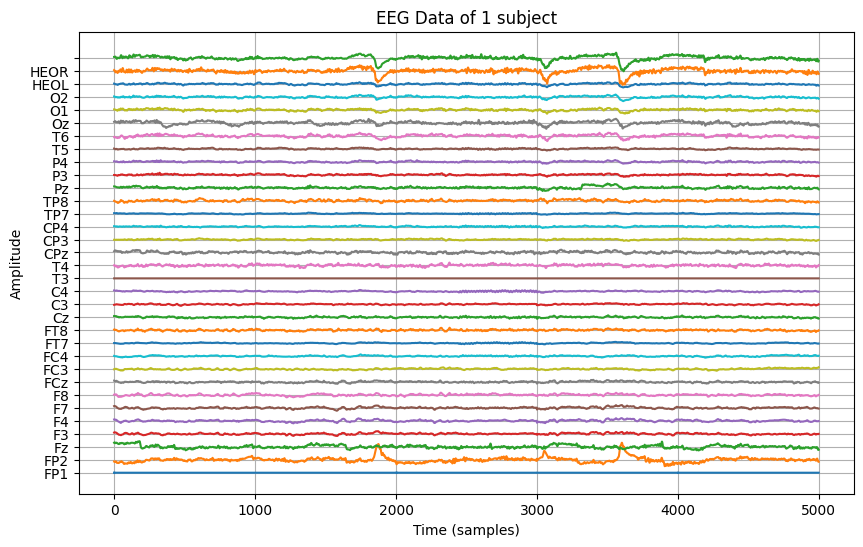

In [ ]:
# @title Plot del segnale EEG
num_channels = len(eeg_channels)
num_samples = eeg_subj.shape[1]
delta = 0.0001
tstart = 5000
tend = 10000
title = 'EEG Data of 1 subject'
plot_eeg(eeg_subj, delta, title, eeg_channels, tstart, tend)

# La tabella EVENTS: Onset del Motor Imagery task e le etichette

La tabella 'events' contiene:

*   ***value*** tipo di evento. se value=1: instruction starts; se value = 2: motor imagery starts; se value = 3: break starts
*   ***onset***: istante iniziale dell'evento specificato nell'attributo 'value'
*   ***duration***: durata di ogni evento
*   ***trial_type*** Se= “1” => left-hand motor imagery tasks.
Se = “2” => right-hand motor imagery tasks





In [ ]:
#  @title Upload della tabella
percorso_events = '/content/drive/MyDrive/PROGETTO D.L./Stroke dataset/task-motor-imagery_events.tsv'
events = pd.read_csv(percorso_events, delimiter='\t')

row_count=10
events.head(row_count)

,onset,duration,trial_type,response_time,value,stim_file
0,1,2000,1,NaN,1,stim1.png
1,2001,4000,1,NaN,2,stim2.mp4
2,6001,2000,1,NaN,3,stim3.png
3,8001,2000,2,NaN,1,stim1.png
4,10001,4000,2,NaN,2,stim2.mp4
5,14001,2000,2,NaN,3,stim3.png
6,16001,2000,1,NaN,1,stim1.png
7,18001,4000,1,NaN,2,stim2.mp4
8,22001,2000,1,NaN,3,stim3.png
9,24001,2000,2,NaN,1,stim1.png


In [ ]:
events[events['value']==2]

,onset,duration,trial_type,response_time,value,stim_file
1,2001,4000,1,NaN,2,stim2.mp4
4,10001,4000,2,NaN,2,stim2.mp4
7,18001,4000,1,NaN,2,stim2.mp4
10,26001,4000,2,NaN,2,stim2.mp4
13,34001,4000,1,NaN,2,stim2.mp4
16,42001,4000,2,NaN,2,stim2.mp4
19,50001,4000,1,NaN,2,stim2.mp4
22,58001,4000,2,NaN,2,stim2.mp4
25,66001,4000,1,NaN,2,stim2.mp4
28,74001,4000,2,NaN,2,stim2.mp4


**Attenzione**: Ho notato che questo file tsv è stato creato prima che venisse fatto il preprocessing dei segnali, quindi tutti i valori di onset della tabella fanno riferimento ad un sampling rate di 1000hz.

Invece, il sampling rate dopo la fase di preprocessing è di 500hz. Quindi divido per due la prima colonna corrispondente all'attributo 'onset'.

In [ ]:
events['onset'] = np.ceil(events['onset']/2).astype(int)
events['duration'] = np.ceil(events['duration']/2).astype(int)

events.head(row_count)

,onset,duration,trial_type,response_time,value,stim_file
0,1,1000,1,NaN,1,stim1.png
1,1001,2000,1,NaN,2,stim2.mp4
2,3001,1000,1,NaN,3,stim3.png
3,4001,1000,2,NaN,1,stim1.png
4,5001,2000,2,NaN,2,stim2.mp4
5,7001,1000,2,NaN,3,stim3.png
6,8001,1000,1,NaN,1,stim1.png
7,9001,2000,1,NaN,2,stim2.mp4
8,11001,1000,1,NaN,3,stim3.png
9,12001,1000,2,NaN,1,stim1.png


Prendo solo i segmenti dei trials corrispondenti ai 4 secondi di immaginazione del movimento => all'interno della tabella events, tutte le righe corrispondenti all'attributo value = 2


In [ ]:
motor_imagery_events = events[events['value']==2]
motor_imagery_events

,onset,duration,trial_type,response_time,value,stim_file
1,1001,2000,1,NaN,2,stim2.mp4
4,5001,2000,2,NaN,2,stim2.mp4
7,9001,2000,1,NaN,2,stim2.mp4
10,13001,2000,2,NaN,2,stim2.mp4
13,17001,2000,1,NaN,2,stim2.mp4
16,21001,2000,2,NaN,2,stim2.mp4
19,25001,2000,1,NaN,2,stim2.mp4
22,29001,2000,2,NaN,2,stim2.mp4
25,33001,2000,1,NaN,2,stim2.mp4
28,37001,2000,2,NaN,2,stim2.mp4


label = “1” for left-hand MI tasks.

label = “2” for right-hand MI tasks

In [ ]:
# @title Lista degli onset e delle labels associate
lista_onset = motor_imagery_events['onset'].tolist()
# onset = time sample corrispondente all'inizio del motor imagery task
lista_labels = motor_imagery_events['trial_type'].tolist()

print(lista_onset)
print(lista_labels)

[1001, 5001, 9001, 13001, 17001, 21001, 25001, 29001, 33001, 37001, 41001, 45001, 49001, 53001, 57001, 61001, 65001, 69001, 73001, 77001, 81001, 85001, 89001, 93001, 97001, 101001, 105001, 109001, 113001, 117001, 121001, 125001, 129001, 133001, 137001, 141001, 145001, 149001, 153001, 157001]
[1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2]


# DATA PROCESSING

In [ ]:
# @title Training, validation e test set con le sliding windows
n_windows = 1  # iperparametro
training_w, training_labels_w =Sliding_windows_dataset(train['Participant_ID'].tolist(), lista_onset, lista_labels, n_windows)
validation_w, validation_labels_w =Sliding_windows_dataset(validation['Participant_ID'].tolist(), lista_onset, lista_labels, n_windows)
test_w, test_labels_w =Sliding_windows_dataset(test['Participant_ID'].tolist(), lista_onset, lista_labels, n_windows)


Extracting EDF parameters from /content/eeg_data/sub-48_task-motor-imagery_eeg.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Extracting EDF parameters from /content/eeg_data/sub-13_task-motor-imagery_eeg.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...


<ipython-input-4-ad103b2f8719>:19: RuntimeWarning: Physical range is not defined in following channels:
CPz
  raw = mne.io.read_raw_edf(edf_file_path)
<ipython-input-4-ad103b2f8719>:19: RuntimeWarning: Physical range is not defined in following channels:
CPz
  raw = mne.io.read_raw_edf(edf_file_path)


Extracting EDF parameters from /content/eeg_data/sub-27_task-motor-imagery_eeg.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Extracting EDF parameters from /content/eeg_data/sub-07_task-motor-imagery_eeg.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...


<ipython-input-4-ad103b2f8719>:19: RuntimeWarning: Physical range is not defined in following channels:
CPz
  raw = mne.io.read_raw_edf(edf_file_path)
<ipython-input-4-ad103b2f8719>:19: RuntimeWarning: Physical range is not defined in following channels:
CPz
  raw = mne.io.read_raw_edf(edf_file_path)


Extracting EDF parameters from /content/eeg_data/sub-34_task-motor-imagery_eeg.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...


...

<ipython-input-4-ad103b2f8719>:19: RuntimeWarning: Physical range is not defined in following channels:
CPz
  raw = mne.io.read_raw_edf(edf_file_path)
<ipython-input-4-ad103b2f8719>:19: RuntimeWarning: Physical range is not defined in following channels:
CPz
  raw = mne.io.read_raw_edf(edf_file_path)


Extracting EDF parameters from /content/eeg_data/sub-28_task-motor-imagery_eeg.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Extracting EDF parameters from /content/eeg_data/sub-45_task-motor-imagery_eeg.edf...
EDF file detected
Setting channel info structure...


<ipython-input-4-ad103b2f8719>:19: RuntimeWarning: Physical range is not defined in following channels:
CPz
  raw = mne.io.read_raw_edf(edf_file_path)
<ipython-input-4-ad103b2f8719>:19: RuntimeWarning: Physical range is not defined in following channels:
CPz
  raw = mne.io.read_raw_edf(edf_file_path)


Creating raw.info structure...
Extracting EDF parameters from /content/eeg_data/sub-47_task-motor-imagery_eeg.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...


<ipython-input-4-ad103b2f8719>:19: RuntimeWarning: Physical range is not defined in following channels:
CPz
  raw = mne.io.read_raw_edf(edf_file_path)


In [ ]:
# Dimensione dei tre set
print('Dimensione del Training set:')
print(training_w.shape)
print(training_labels_w.shape)

print('\nDimensione del Validation set:')
print(validation_w.shape)
print(validation_labels_w.shape)

print('\nDimensione del Test set:')
print(test_w.shape)
print(test_labels_w.shape)

Dimensione del Training set:
(1200, 30, 2000)
(1200,)

Dimensione del Validation set:
(400, 30, 2000)
(400,)

Dimensione del Test set:
(400, 30, 2000)
(400,)


## **Normalization**


Utilizzo la funzione [mne.decoding.Scaler](https://mne.tools/stable/generated/mne.decoding.Scaler.html#mne.decoding.Scaler).

Poi uso la funzione .fit solamente sui dati di Training, per poi trasformare quelli dei Validation e Test set.

In [ ]:
x_train=np.copy(training_w)
x_valid=np.copy(validation_w)
x_test=np.copy(test_w)

myscaler = mne.decoding.Scaler(scalings='mean')
myscaler.fit(x_train)


train_data = myscaler.transform(x_train)
val_data = myscaler.transform(x_valid)
test_data = myscaler.transform(x_test)

In [ ]:
# @title Verifica della normalizzazione

mean_train = np.mean(train_data)
std_train = np.std(train_data)

mean_valid = np.mean(val_data)
std_valid = np.std(val_data)

mean_test = np.mean(test_data)
std_test = np.std(test_data)

print(f"Training set: Mean = {mean_train:.5f}, Standard Deviation = {std_train:.5f}")
print(f"Validation set: Mean = {mean_valid:.5f}, Standard Deviation = {std_valid:.5f}")
print(f"Test set: Mean = {mean_test:.5f}, Standard Deviation = {std_test:.5f}")

Training set: Mean = -0.00000, Standard Deviation = 0.98319
Validation set: Mean = -0.00712, Standard Deviation = 0.62483
Test set: Mean = 0.00497, Standard Deviation = 0.98138


In [ ]:
# check degli outliers
train_data_flattened = train_data.reshape(-1)

# Calcolo lo z score
z_scores = np.abs(train_data_flattened)

# Identify outliers (Z-score > 4*dev_standard => z_score > 4)
outliers = np.where(z_scores > 4)[0]

print("Number of outliers detected:", len(outliers))
print("Percentage of outliers:", len(outliers) / len(train_data_flattened) * 100, "%")



Number of outliers detected: 508725
Percentage of outliers: 0.7065625 %


###  EEG plots pre e post Normalizzazione

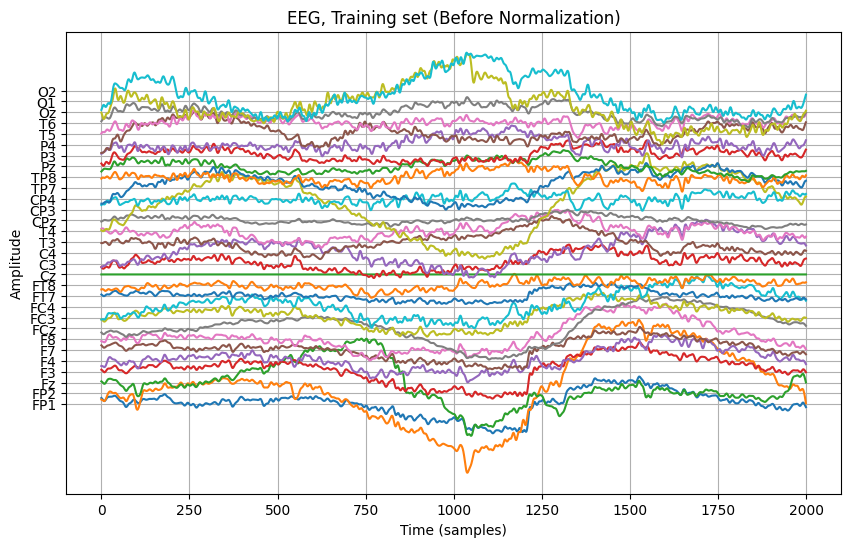

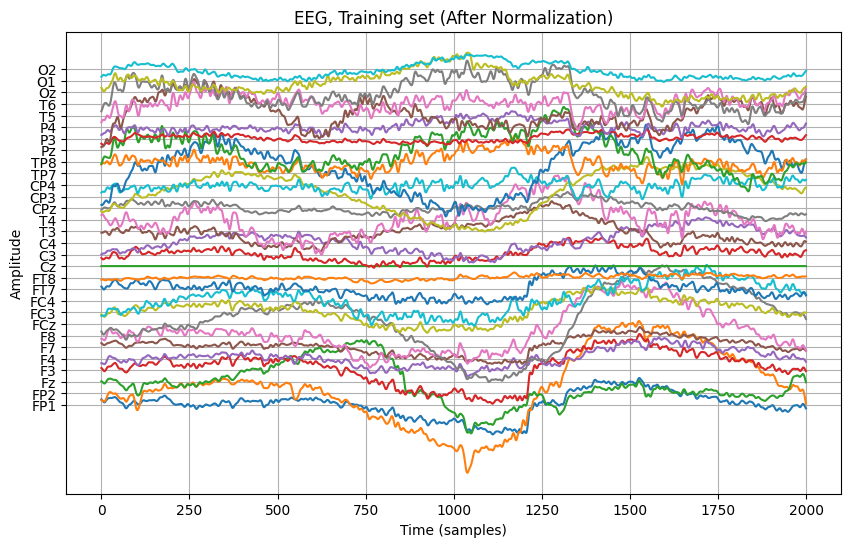

In [ ]:
# @title EEG plots dei dati del Training set
n_windows, n_channels, time_samples = training_w.shape

# Before normalization
EEG_train_before = training_w.transpose(1, 0, 2).reshape(n_channels, n_windows * time_samples)
delta_before = determine_delta(EEG_train_before)

# After normalization
EEG_train_after = train_data.transpose(1, 0, 2).reshape(n_channels, n_windows * time_samples)
delta_after = determine_delta(EEG_train_after)

# Plot
tstart =  5 * 40 * 2000  # cambiare questi numeri per vedere gli altri trials
tend = tstart + 2000
plot_eeg(EEG_train_before, delta_before, 'EEG, Training set (Before Normalization)', eeg_channels, tstart, tend)
plot_eeg(EEG_train_after, delta_after, 'EEG, Training set (After Normalization)', eeg_channels, tstart, tend)


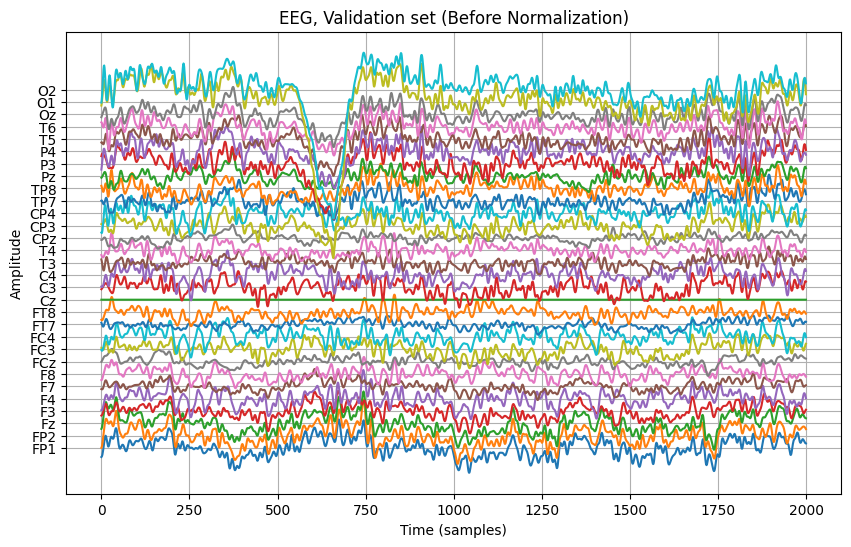

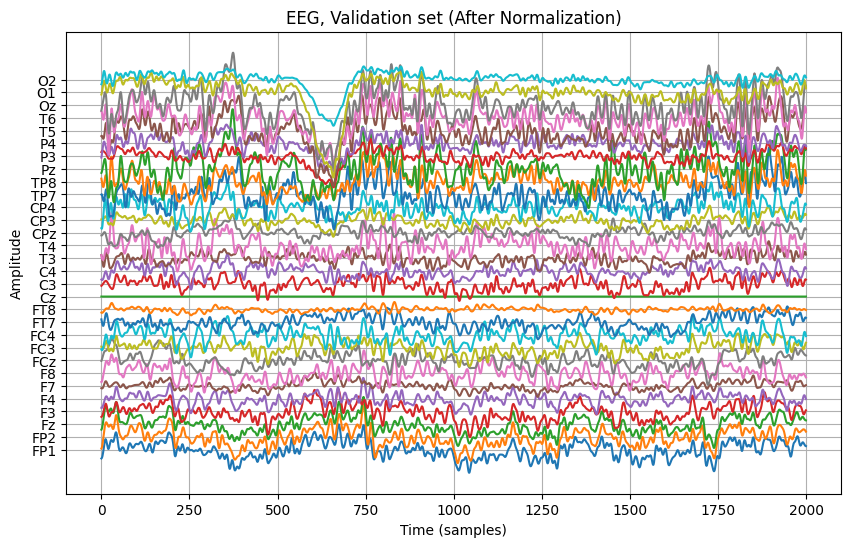

In [ ]:
# @title EEG plots dei dati del Validation set

EEG_valid_before = validation_w.transpose(1, 0, 2).reshape(n_channels, validation_w.shape[0] * time_samples)
delta_before = determine_delta(EEG_valid_before)

EEG_valid_after = val_data.transpose(1, 0, 2).reshape(n_channels, validation_w.shape[0] * time_samples)
delta_after = determine_delta(EEG_valid_after)


# Plot
tstart = 160 * 2000
tend = tstart + 2000
plot_eeg(EEG_valid_before, delta_before, 'EEG, Validation set (Before Normalization)', eeg_channels, tstart, tend)
plot_eeg(EEG_valid_after, delta_after, 'EEG, Validation set (After Normalization)', eeg_channels, tstart, tend)


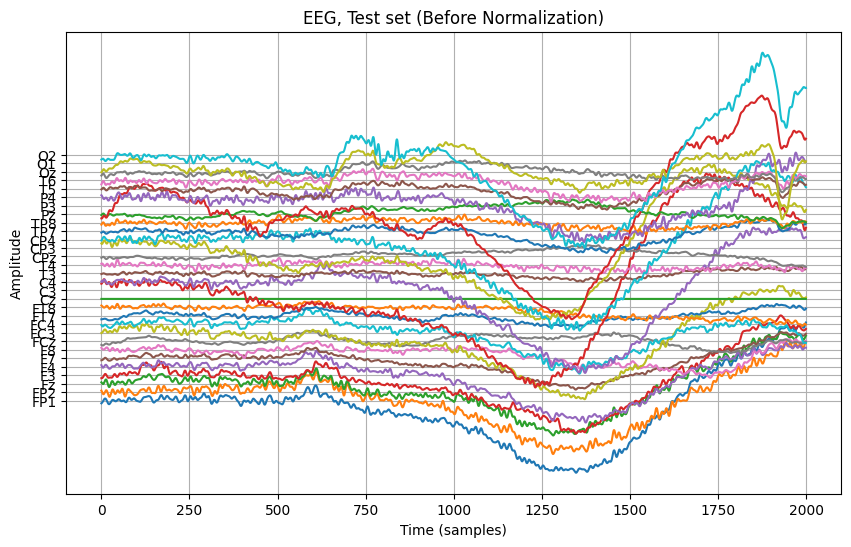

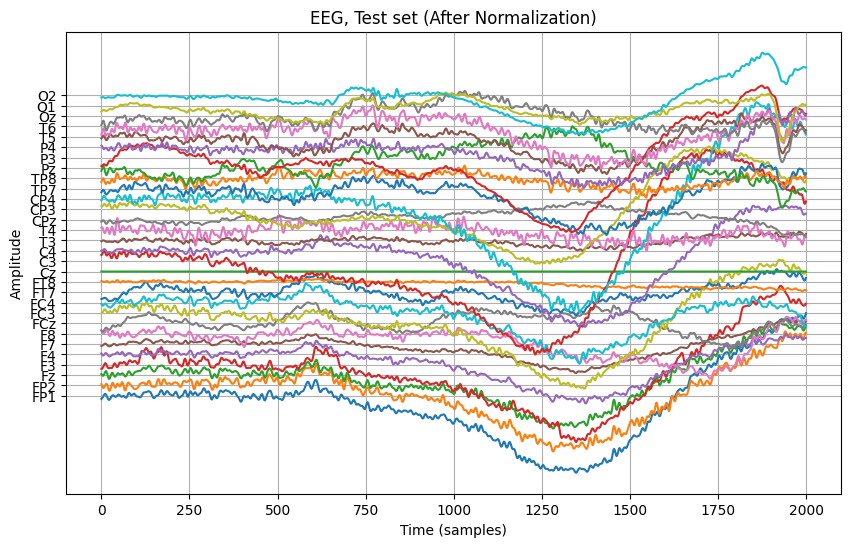

In [ ]:
# @title EEG plots dei dati del Test set
EEG_test_before = test_w.transpose(1, 0, 2).reshape(n_channels, test_w.shape[0] * time_samples)
delta_before = determine_delta(EEG_test_before)

EEG_test_after = test_data.transpose(1, 0, 2).reshape(n_channels, test_w.shape[0] * time_samples)
delta_after = determine_delta(EEG_test_after)

# Plot
tstart = 160 * 2000
tend = tstart + 2000
plot_eeg(EEG_test_before, delta_before, 'EEG, Test set (Before Normalization)', eeg_channels, tstart, tend)
plot_eeg(EEG_test_after, delta_after, 'EEG, Test set (After Normalization)', eeg_channels, tstart, tend)


In [ ]:
print('Dimensione del Training set:')
print(train_data.shape)
print(training_labels_w.shape)

print('\nDimensione del Validation set:')
print(val_data.shape)
print(validation_labels_w.shape)

print('\nDimensione del Test set:')
print(test_data.shape)
print(test_labels_w.shape)

Dimensione del Training set:
(1200, 30, 2000)
(1200,)

Dimensione del Validation set:
(400, 30, 2000)
(400,)

Dimensione del Test set:
(400, 30, 2000)
(400,)


## One-hot encoding delle labels

In [ ]:
# one-hot encoding delle labels
training_labels = to_categorical(training_labels_w - 1)
validation_labels = to_categorical(validation_labels_w - 1)
test_labels = to_categorical(test_labels_w - 1)

print(training_labels.shape)
print(validation_labels.shape)
print(test_labels.shape)


(1200, 2)
(400, 2)
(400, 2)


## Distribuzione dei dati nei tre set

I dati da dare in input a [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) e a [TSNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html) devono essere in maniera tale da avere per colonne le features

Nel caso di dati EEG devo trattare ogni punto (channel-time) come una specifica feature


### **PCA**


In [ ]:
# I Reshape the data for PCA and TSNE (flatten the time dimension)
n_train, n_channels, n_time = train_data.shape
n_valid = val_data.shape[0]
n_test = test_data.shape[0]

#I Reshape the data to have samples as rows and flattened features (channels * time) as columns.
train_flat = train_data.reshape(n_train, n_channels * n_time)
val_flat = val_data.reshape(n_valid, n_channels * n_time)
test_flat = test_data.reshape(n_test, n_channels * n_time)

In [ ]:
print(train_flat.shape)

(1200, 60000)


In [ ]:
# Inizializzo la PCA e uso la funzione fit sul training set
pca = PCA(n_components=2)
train_pca = pca.fit_transform(train_flat)

# trasformo validation e test set usando la PCA fittata sui dati di training
val_pca = pca.transform(val_flat)
test_pca = pca.transform(test_flat)

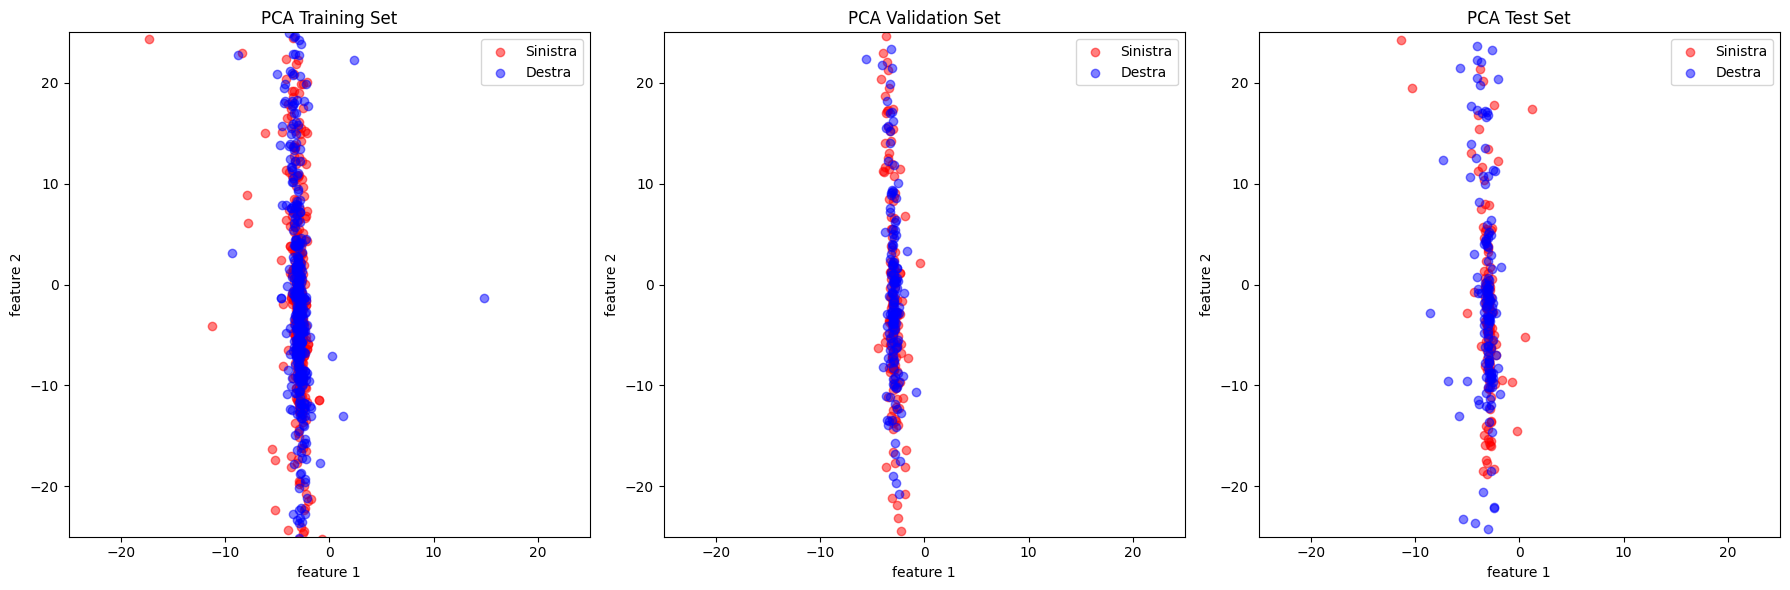

In [ ]:
# @title Visualizzazione after PCA
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plot_2features(train_pca, training_labels_w, 'PCA Training Set')
plt.ylim(-25, 25)
plt.xlim(-25, 25)

plt.subplot(1, 3, 2)
plot_2features(val_pca, validation_labels_w, 'PCA Validation Set')
plt.ylim(-25, 25)
plt.xlim(-25, 25)


plt.subplot(1, 3, 3)
plot_2features(test_pca, test_labels_w, 'PCA Test Set')
plt.ylim(-25, 25)
plt.xlim(-25, 25)


plt.tight_layout()
plt.show()

In [ ]:
# PCA sui soggetti presi singolarmente
train_flat_1sbj = train_flat[0:40] # primo soggetto = 0:40*n_windows, secondo soggetto = 40*n_windows:80*n_windows  e così via
train_labels_1sbj = training_labels_w[0:40]

val_flat_1sbj = val_flat[0:40]
val_labels_1sbj = validation_labels_w[0:40]

test_flat_1sbj = test_flat[0:40]
test_labels_1sbj = test_labels_w[0:40]

In [ ]:
# Inizializzo la PCA e uso la funzione fit sul training set
pca = PCA(n_components=2)
train_pca = pca.fit_transform(train_flat_1sbj)

# trasformo validation e test set usando la PCA fittata sui dati di training
val_pca = pca.transform(val_flat_1sbj)
test_pca = pca.transform(test_flat_1sbj)

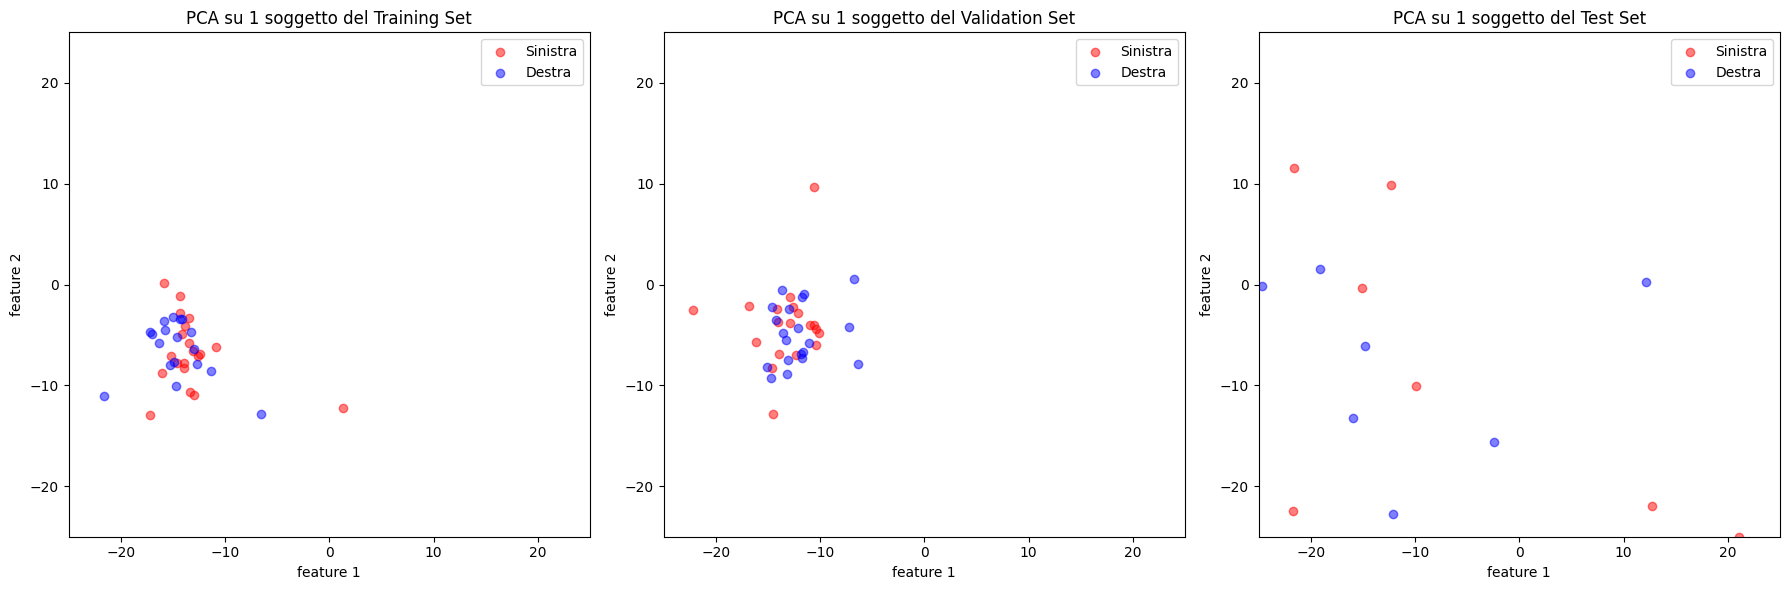

In [ ]:
# @title Visualizzazione after PCA dei soggetti singoli
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plot_2features(train_pca, train_labels_1sbj, 'PCA su 1 soggetto del Training Set')
plt.ylim(-25, 25)
plt.xlim(-25, 25)

plt.subplot(1, 3, 2)
plot_2features(val_pca, val_labels_1sbj, 'PCA su 1 soggetto del Validation Set')
plt.ylim(-25, 25)
plt.xlim(-25, 25)


plt.subplot(1, 3, 3)
plot_2features(test_pca, test_labels_1sbj, 'PCA su 1 soggetto del Test Set')
plt.ylim(-25, 25)
plt.xlim(-25, 25)


plt.tight_layout()
plt.show()

### **TSNE**

In [ ]:
# Inizializzo la t-SNE e uso la funzione .fit sul training set
tsne = TSNE(n_components=2, random_state=42)
train_sne = tsne.fit_transform(train_flat)

# Trasformo validation e test sets
val_tsne = tsne.fit_transform(val_flat)
test_tsne = tsne.fit_transform(test_flat)

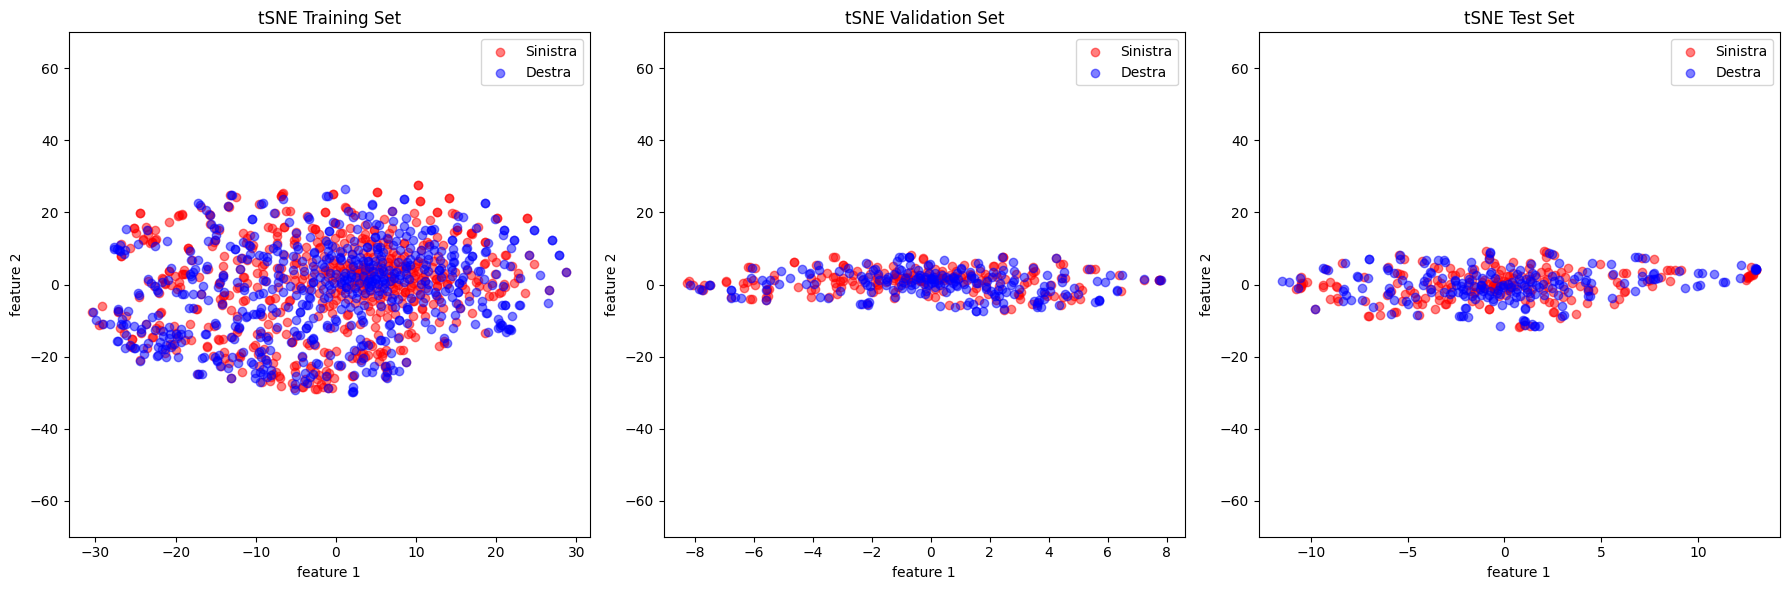

In [ ]:
# @title Visualizzazione after TSNE
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plot_2features(train_sne, training_labels_w, 'tSNE Training Set')
plt.ylim(-70, 70)

plt.subplot(1, 3, 2)
plot_2features(val_tsne, validation_labels_w, 'tSNE Validation Set')
plt.ylim(-70, 70)

plt.subplot(1, 3, 3)
plot_2features(test_tsne, test_labels_w, 'tSNE Test Set')
plt.ylim(-70, 70)

plt.tight_layout()
plt.show()

*Come si può osservare dai grafici della PCA (sia sui soggetti messi insieme che presi singolarmente) e TSNE, non è possibile discriminare chiaramente l'immaginazione della mano sinistra e della mano destra in due dimensioni (utilizzando due feature), infatti i dati delle due categorie risultano completamente mescolati.
Questo suggerisce che sarà molto difficile in seguito per il modello sviluppato discriminare tra le due classi.*

## Datasets reshape
*Voglio i dataset nella forma: (examples,time_samples, channels)*

In [ ]:
# runnare questa cella una sola volta, nel caso contrario runnare fino ad ottenere la forma: (examples,time_samples, channels = 30)
train_data = train_data.transpose(0, 2, 1)
val_data = val_data.transpose(0, 2, 1)
test_data = test_data.transpose(0, 2, 1)

print("Data shape:", train_data.shape)
time_samples = train_data.shape[1]

Data shape: (1200, 2000, 30)


# THE MODEL: LSTM


*Parto da un modello molto semplice, per poi rendere l'architettura più complessa.
All'inizio lancio l'addestramento con 200/300 epoche e senza l'early stopping per vedere se almeno sul training set la loss scende.*

## MODEL DEFINITION



```
# Modello molto complesso

def build_LSTM(timesteps,feature_count):
  model = keras.Sequential(
      [
        layers.Input(shape=(timesteps,feature_count)),
        layers.Bidirectional(layers.LSTM(30, return_sequences=True)),    # many-to-many
        layers.BatchNormalization(),
        layers.LeakyReLU(alpha=0.05),
        layers.Dropout(0.4),
        layers.Bidirectional(layers.LSTM(30, return_sequences=True)),    # many-to-many
        layers.BatchNormalization(),
        layers.LeakyReLU(alpha=0.05),
        layers.Dropout(0.3),
        layers.Bidirectional(layers.LSTM(10, return_sequences=False)),    # many-to-one
        layers.Dense(2,activation='softmax')
      ]
    )
  return model
```



In [ ]:
def Build_net(timesteps,feature_count):
  model = keras.Sequential(
      [
          layers.Input(shape=(timesteps,feature_count)),
          layers.LSTM(30),
          layers.BatchNormalization(),
          layers.LeakyReLU(),
          layers.Dropout(0.2),
          layers.Dense(2,activation='softmax')
      ]
  )
  return model

## Model creation

In [ ]:
my_RNN= Build_net(time_samples,n_channels)

# Print the model summary
my_RNN.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 30)                  │           7,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 30)                  │             120 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu (LeakyReLU)              │ (None, 30)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 30)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 2)                   │              62 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 7,502 (29.30 KB)

 Trainable params: 7,442 (29.07 KB)

 Non-trainable params: 60 (240.00 B)

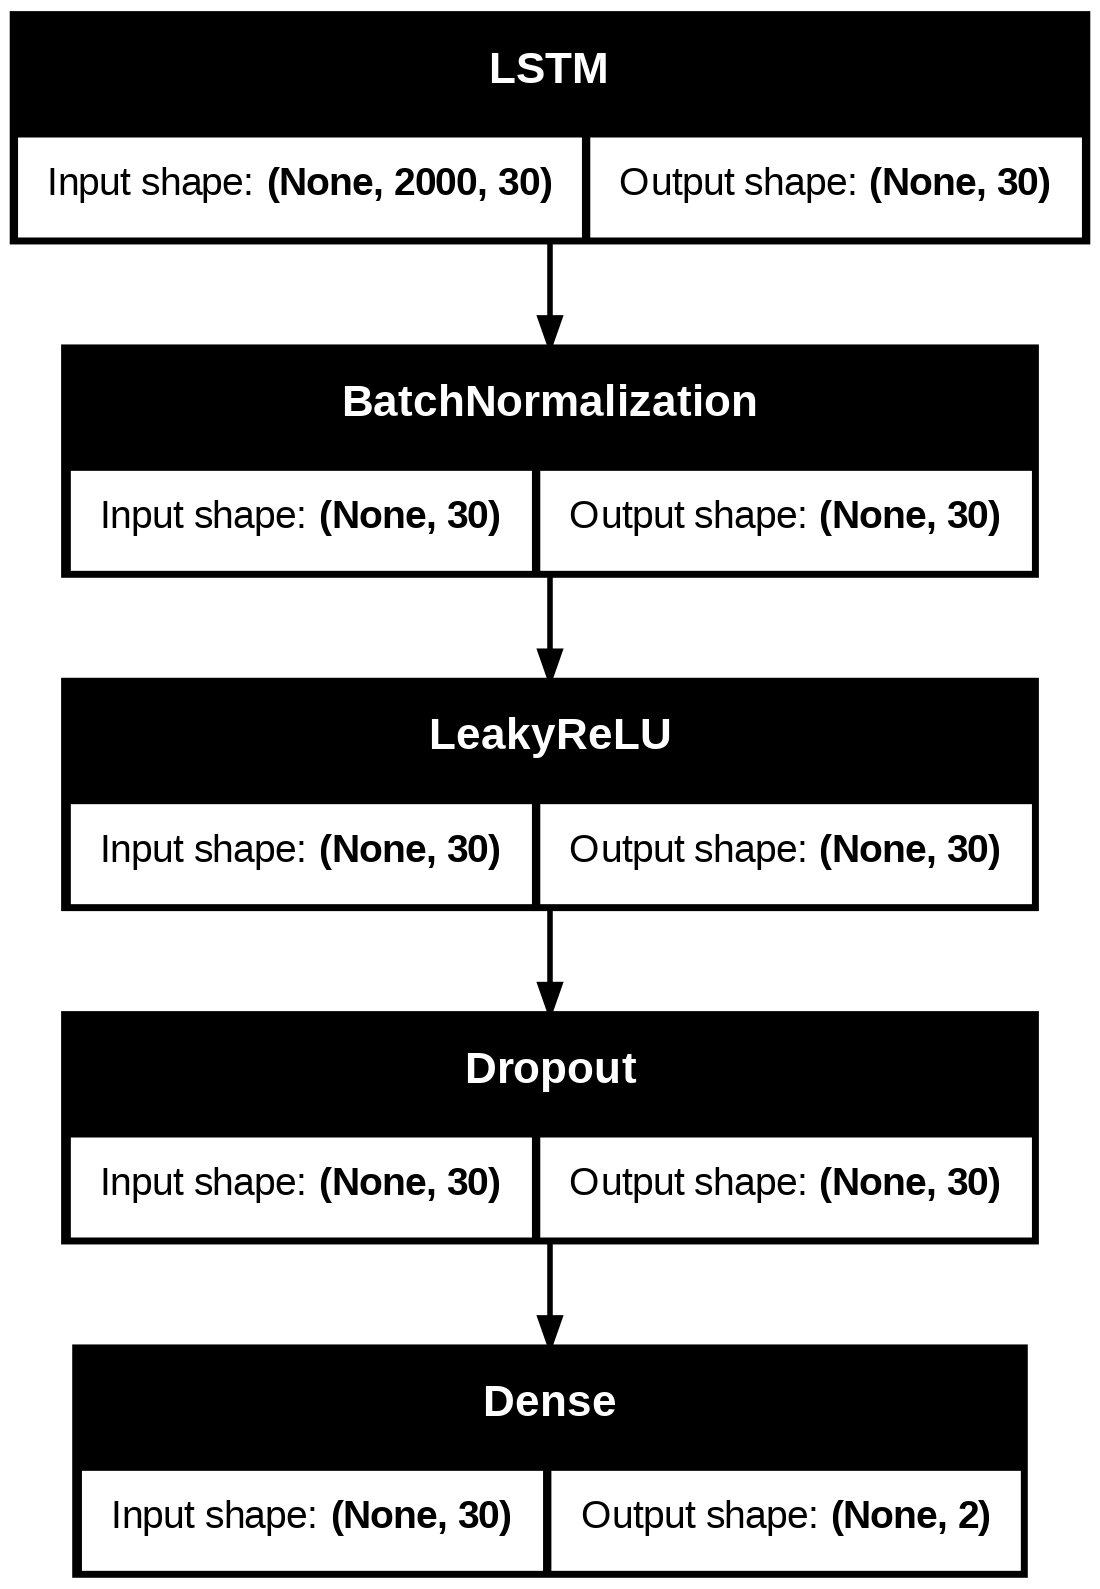

In [ ]:
keras.utils.plot_model(my_RNN,show_shapes=True, show_layer_names=False)

In [ ]:
my_RNN.compile(optimizer='Adam', loss='categorical_crossentropy', metrics=['accuracy'])


## Training del modello

In [ ]:
epoch_count = 100
#patience = 15
mini_batch = n_windows*40*3 # -> 3 soggetti alla volta (4windows x 40trials x n_soggetti)
#early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True)

history = my_RNN.fit(train_data, training_labels,
                    validation_data=(val_data, validation_labels),
                    epochs=epoch_count,
                    batch_size=mini_batch)
                    #callbacks=[early_stop])

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.4992 - loss: 0.8409 - val_accuracy: 0.4600 - val_loss: 0.6993
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 598ms/step - accuracy: 0.4908 - loss: 0.8134 - val_accuracy: 0.4600 - val_loss: 0.6977
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 637ms/step - accuracy: 0.5042 - loss: 0.7967 - val_accuracy: 0.4825 - val_loss: 0.6963
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 727ms/step - accuracy: 0.4883 - loss: 0.7899 - val_accuracy: 0.5075 - val_loss: 0.6952
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 714ms/step - accuracy: 0.4800 - loss: 0.7809 - val_accuracy: 0.5075 - val_loss: 0.6943
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.4967 - loss: 0.7555 - val_accuracy: 0.5025 - val_loss: 0.6937
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.5317 - loss: 0.7411 - val_accuracy: 0.5175 - val_loss: 0.6932
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 597ms/step - accuracy: 0.5125 - loss: 0.7600 - val_accuracy: 0.5250 - val_loss: 

## Visualizzazione dell'addestramento

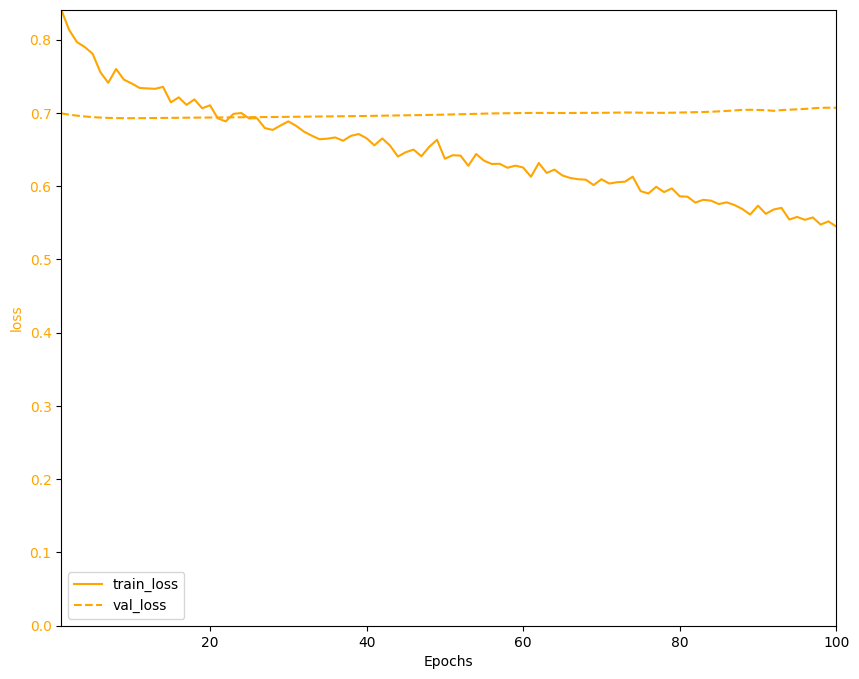

In [ ]:
plot_history(history)

# Risultati e Conclusioni
*L'accuratezza sul validation set rimane intorno al 50% al variare della complessità del modello. Questo indica che il modello ha difficoltà significative nel discriminare tra le due classi (destra e sinistra) sui dati di validazione.*

*Durante l'addestramento sui dati di training, l'accuratezza aumenta con l'incrementare della complessità del modello, raggiungendo valori dell'80-90%. Tuttavia, questo comportamento suggerisce un problema di overfitting, poiché si osserva un aumento significativo della loss sul validation set con l'avanzare delle epoche.*

![the excel file](https://drive.google.com/uc?export=view&id=11oxkDCmpuTk4KIxOCUjv0wL77fzS9Haq)

Nonostante gli scarsi risultati ottenuti da tutti i modelli utilizzati in precedenza, qui di seguito valuto le performance su test set del seguente modello:

```
   model = keras.Sequential(
      [
          layers.Input(shape=(timesteps,feature_count)),
          layers.LSTM(30),
          layers.BatchNormalization(),
          layers.LeakyReLU(),
          layers.Dropout(0.2),
          layers.Dense(2,activation='softmax')
      ]
  )
  return model
```



In [ ]:
# @title  Predizioni sul Test Set
test_predictions = my_RNN.predict(test_data)
print('dimensione di test_predictions:',test_predictions.shape)

print('Un esempio delle prime 5 predizioni:\n',test_predictions[0:5])
# Prendo la probabilità più alta di appartenere alla classe per ogni predizione
predicted_classes = np.argmax(test_predictions, axis=1)

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step
dimensione di test_predictions: (400, 2)


Posso usare direttamente la funzione [evaluate](https://keras.io/api/models/model_training_apis/#evaluate-method) che prende in input i dati e le labels del test set e restituisce il valore della loss e dell'accuratezza ottenute

In [ ]:
# Valutazione sul Test Set
results = my_RNN.evaluate(test_data, test_labels, return_dict = True)
#print(results)

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step - accuracy: 0.4939 - loss: 0.7307
